# Volume rendering: pictures of any quantity

A projection reduces a quantity along the line of sight: a sum for `:sd` and `:mass` (and for anything with `mode=:sum`), a weighted mean for everything else. **Volume rendering** instead gives every
cell a **colour** and an **opacity** from its value, and lets the gas in front cover the gas
behind it:

    α = 1 − e^(−σ(v) ℓ),      colour += (what is still visible) · α · colour(v)

`ℓ` is the path through the cell, so opacity is set **per unit length**: `tau_unit_length=[300, :pc]`
means the most opaque gas reaches optical depth 1 over 300 pc. Because of that the picture stays
the same when you change the pixel size or zoom in, which is not true of a renderer that uses a
fixed opacity per step.

This is a tool for **illustrations**: the colours and the opacity are choices, not measurements.
For maps with physical units use [`projection`](@ref).

| function | what it does |
|:--|:--|
| [`volumerender`](@ref) | one picture |
| [`volumeorbit`](@ref) | turn around the object, one look for every frame |
| [`volumepath`](@ref) | move the camera between keyframes: angles, centre and zoom |
| [`volumelook`](@ref) | resolve colours and opacity once, and reuse them |

All colour maps on this page are colour-blind friendly: `:viridis`, `:cividis`, `:magma`,
`:inferno` and `:plasma`. If you want the reach of a rainbow, use a scientific one such as
`:roma` or `:batlow` (Crameri), which keep an even lightness and stay readable for colour-blind
readers. For a signed quantity, one that runs from negative through zero to positive, use
a diverging map such as `:vik` or `:berlin`.

## 1. Every parameter at a glance

The whole renderer is this table. Everything below it is one of these settings varied on the
same galaxy, so you can come back here once you know what you are looking for.

| parameter | what it decides |
|:--|:--|
| `unit` | the unit the quantity is read in, e.g. `:nH` for a density in cm⁻³ |
| `scale` | `:log` (default) or `:linear`: how values are spread across the colour range |
| `colorrange=(lo, hi)` | which values get colour. Below `lo` is transparent (with `opacity` starting at 0), above `hi` looks like `hi`. Without it, `percentiles` of the cell values are used. |
| `colormap` | the colours; `:viridis`, `:cividis`, `:magma`, `:inferno`, `:plasma`, or `:roma`/`:batlow` |
| `opacity=(lo, hi)` | the ends of the opacity ramp across the colour range |
| `opacity_gamma` | bends that ramp; above 1 keeps faint gas transparent so only the densest parts are solid |
| `iso=[…]`, `iso_width`, `iso_alpha` | surfaces at chosen values (section 8) |
| `tau_unit_length=[L, :pc]` | the length over which the most opaque gas reaches optical depth 1 |
| `tau_target` | used instead, when `tau_unit_length` is not given: the median optical depth of the map |
| `exposure` | brightens the finished picture, like a camera exposure |
| `tone` | what happens to light brighter than white: `:aces` (default) and `:reinhard` bend it so bright gas fades toward white and keeps its detail; `:linear` cuts it off, which holds full saturation and flattens bright regions |
| `background` | `:black` (default), `:white`, or any colour |
| `supersample` | sub-pixels per side, `:auto` by default |
| view keywords | `direction`, `inclination`, `azimuth`, `axis`, `position_angle`, `center`, `range_unit`, `xrange`/`yrange`/`zrange`, `pxsize` or `res` |

The next sections show what the important ones do to the same galaxy.

The ones that decide whether a picture works at all are `colorrange`, `opacity_gamma`,
`tau_unit_length` and `exposure`, in that order.


## 2. Setup

One galaxy, two views: a detailed one at 30 pc pixels for single pictures, and a coarser one at
60 pc for the panels that compare settings side by side.

In [1]:
# Example-data root. Point this at your own simulation folder, or set the
# MERA_EXAMPLES environment variable; every path below is built from it.
MERA_EXAMPLES = get(ENV, "MERA_EXAMPLES", "/Volumes/FASTStorage/Simulations/Mera-Tests");

using Mera, CairoMakie
CairoMakie.activate!()
info = getinfo(300, joinpath(MERA_EXAMPLES, "RAMSES/mw_L10"), verbose=false)
gas  = gethydro(info, verbose=false, show_progress=false)

# a 32 × 32 × 12 kpc box, seen at 70 degrees from the spin axis
view  = (inclination=70, axis=:angmom, center=[:bc], range_unit=:kpc,
         xrange=[-16, 16], yrange=[-16, 16], zrange=[-6, 6], pxsize=[30, :pc], verbose=false)
panel = Base.setindex(view, [60, :pc], :pxsize)     # the same view, coarser, for comparison grids

function show_image!(pos, m; title="")
    x0, x1, y0, y1 = getextent(m, :kpc)
    ax = Axis(pos, title=title, xlabel="x [kpc]", ylabel="y [kpc]", aspect=DataAspect())
    image!(ax, x0..x1, y0..y1, m.image)     # the image is indexed [ix, iy], like a map
    return ax
end
println("gas cells = ", length(gas.data), ",  threads = ", Threads.nthreads())


*__   __ _______ ______   _______ 


|  |_|  |       |    _ | |   _   |
|       |    ___|   | || |  |_|  |
|       |   |___|   |_||_|       |
|       |    ___|    __  |       |
| ||_|| |   |___|   |  | |   _   |
|_|   |_|_______|___|  |_|__| |__|
Mera v1.8.0 | Julia 1.12.7 | 8 threads



gas cells = 28320979

,  threads = 8


## 3. The first picture

`volumerender` needs a quantity. Everything else has a default, and the opacity strength is taken
from the data unless you set it.

VolumeRenderType: 1075 × 742 pixels, :rho

, filled 15.4 %   (23.0 s)
VolumeLook(:rho in :nH, log (-2.0

, 2.0), :inferno, opacity (0.0, 1.0), exposure 2.5, τ=1 over 120.0 pc)


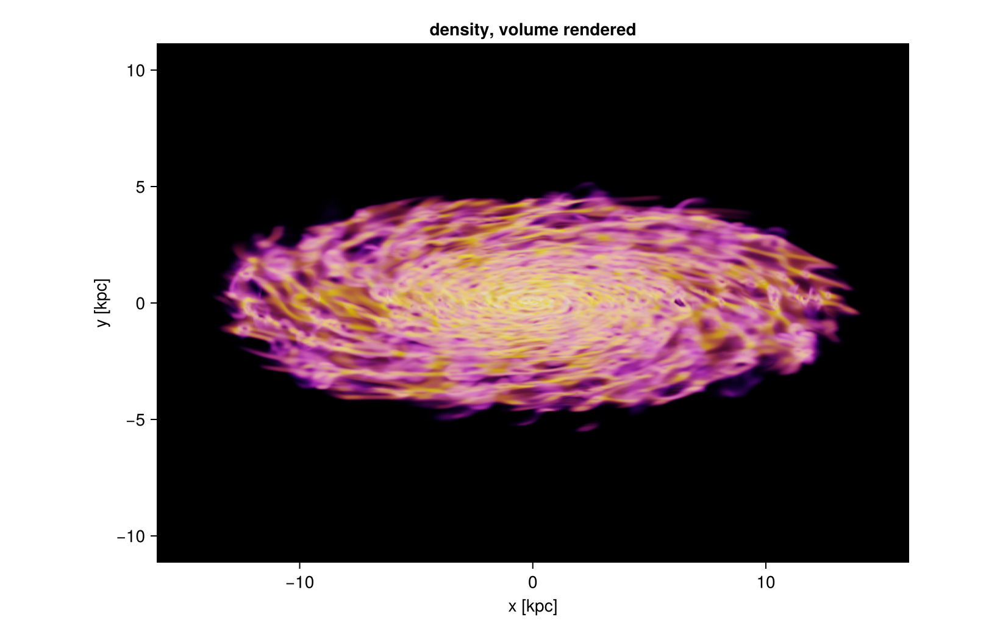

In [2]:
t = @elapsed m = volumerender(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), colormap=:inferno,
                              opacity_gamma=2.5, tau_unit_length=[120, :pc], exposure=2.5, view...)
println(m, "   (", round(t, digits=1), " s)")
println(m.look)

fig = Figure(size=(820, 520))
show_image!(fig[1, 1], m; title="density, volume rendered")
fig

These four settings are a good starting point for a galaxy, and the rest of the page varies them
one at a time:

* `colorrange=(1e-2, 1e2)`: colour only the gas that matters, not the empty halo
* `opacity_gamma=2.5`: keep the thin haze transparent so the structure stands out
* `tau_unit_length=[120, :pc]`: dense gas becomes solid over about a hundred parsecs
* `exposure=2.5`: bright enough without washing the picture out
* `tone=:aces` (the default): bright gas rolls off toward white instead of turning into a
  saturated patch. Rendering with `tone=:linear` at the same exposure looks harsher, because
  every value above white is simply cut.


## 4. The transfer functions themselves

Two curves decide everything: how a value becomes a **colour**, and how it becomes an **opacity**.
Both live on the colour range. The plot below shows them for the settings used above and for two
variations, so you can see what `opacity`, `opacity_gamma` and `iso` really change.

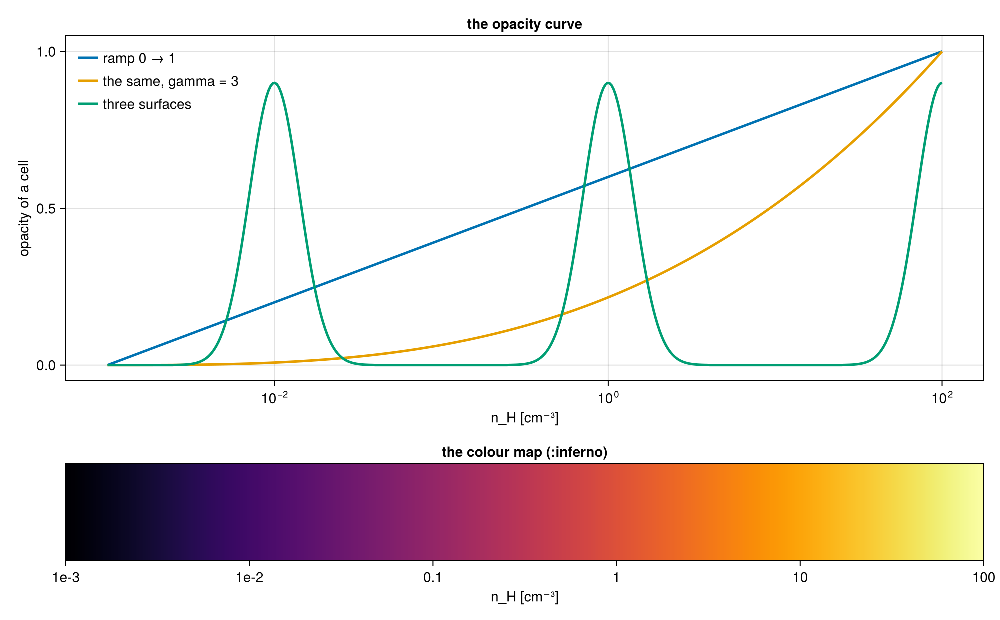

In [3]:
# rebuild the opacity curve of a look, so it can be drawn
opacity_curve(l, v) = Mera._look_alpha(l, Mera._look_t(l, v))

vals  = 10 .^ range(-3, 2, length=400)                       # n_H from 1e-3 to 1e2
base  = volumelook(gas, :rho; unit=:nH, colorrange=(1e-3, 1e2), opacity=(0.0, 1.0),
                   tau_unit_length=[300, :pc], panel...)
soft  = volumelook(gas, :rho; unit=:nH, colorrange=(1e-3, 1e2), opacity=(0.0, 1.0),
                   opacity_gamma=3, tau_unit_length=[300, :pc], panel...)
shell = volumelook(gas, :rho; unit=:nH, colorrange=(1e-3, 1e2), opacity=(0.0, 0.0),
                   iso=[0.01, 1.0, 100.0], iso_width=0.15, iso_alpha=0.9,
                   tau_unit_length=[300, :pc], panel...)

fig = Figure(size=(1000, 620))
ax1 = Axis(fig[1, 1], xscale=log10, xlabel="n_H [cm⁻³]", ylabel="opacity of a cell",
           title="the opacity curve")
lines!(ax1, vals, opacity_curve.(Ref(base), vals),  label="ramp 0 → 1", linewidth=2.5)
lines!(ax1, vals, opacity_curve.(Ref(soft), vals),  label="the same, gamma = 3", linewidth=2.5)
lines!(ax1, vals, opacity_curve.(Ref(shell), vals), label="three surfaces", linewidth=2.5)
axislegend(ax1, position=:lt, framevisible=false)

# the colour curve: the colour map across the same range, drawn in "position in the range"
strip = repeat(Mera.RGB{Float64}.(get(Mera.colorschemes[:inferno], range(0, 1, length=256))), 1, 2)
ticks = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]
ax2 = Axis(fig[2, 1], xlabel="n_H [cm⁻³]", title="the colour map (:inferno)",
           yticksvisible=false, yticklabelsvisible=false,
           xticks=([Mera._look_t(base, v) for v in ticks], ["1e-3", "1e-2", "0.1", "1", "10", "100"]))
image!(ax2, 0..1, 0..1, strip)
rowsize!(fig.layout, 2, Relative(0.22))
fig

The opacity curve says how solid a cell of a given value is; `tau_unit_length` then turns that
into a real optical depth over a real length. The colour curve says which colour it gets. Nothing
else is hidden: these two curves plus the length scale are the whole model.

## 5. Opacity is set per length

A short `tau_unit_length` makes the gas solid, so you see its surface; a long one makes it glassy
and you look through the disc.

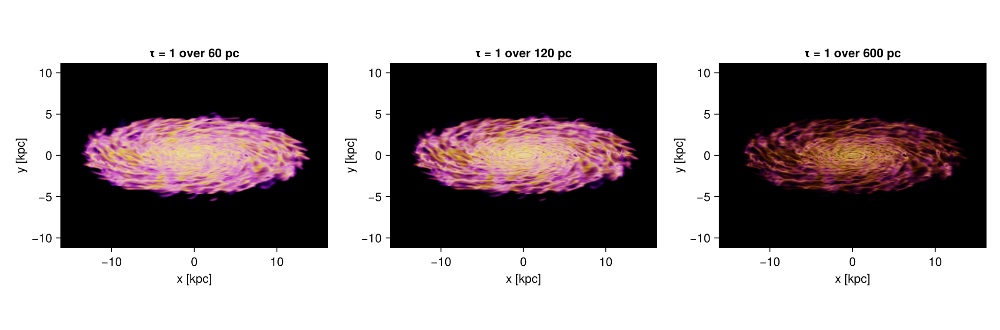

In [4]:
fig = Figure(size=(1150, 380))
for (k, L) in enumerate((60, 120, 600))
    mk = volumerender(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), colormap=:inferno,
                      opacity_gamma=2.5, tau_unit_length=[L, :pc], exposure=2.5, panel...)
    show_image!(fig[1, k], mk; title="τ = 1 over $L pc")
end
fig

Because opacity is per length, the picture does not depend on how finely you sample it. The same
render at 240 pc and at 30 pc pixels differs in sharpness, not in brightness or depth.

pixels of 240 pc: (

137, 95), filled 14.9 %


pixels of 30 pc: (

1075, 742), filled 15.4 %


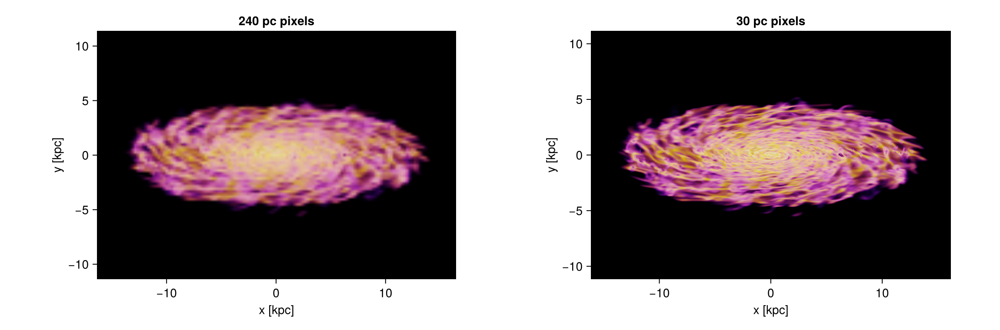

In [5]:
fig = Figure(size=(1150, 380))
for (k, px) in enumerate((240, 30))
    mk = volumerender(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), colormap=:inferno,
                      opacity_gamma=2.5, tau_unit_length=[120, :pc], exposure=2.5,
                      Base.setindex(view, [px, :pc], :pxsize)...)
    println("pixels of $px pc: ", size(mk.image), ", filled ",
            round(100 * sum(mk.alpha) / length(mk.alpha), digits=1), " %")
    show_image!(fig[1, k], mk; title="$px pc pixels")
end
fig

## 6. When a picture comes out too dark

A thin, see-through rendering collects little light, so it looks dark. Four levers help, in this
order:

1. **`exposure`** brightens the finished picture, like a longer exposure on a camera. With the
   default `tone=:aces` the bright end rolls off smoothly, so a high exposure fades toward white
   rather than clipping into a flat patch.
2. **A shorter `tau_unit_length`** makes the gas itself more opaque, so more of it contributes.
3. **A narrower `colorrange`** puts the colours where your gas actually is, instead of spending
   them on empty space.
4. **A steeper `opacity_gamma`** keeps the thin haze transparent, so the bright structure is not
   buried under fog. Brightening alone makes a picture pale; brightening the structure while the
   haze stays dark is what gives it depth.

A colour map that is bright at its low end, such as `:viridis` or `:cividis`, also helps: `:inferno`
and `:magma` start at black, which makes thin gas disappear.

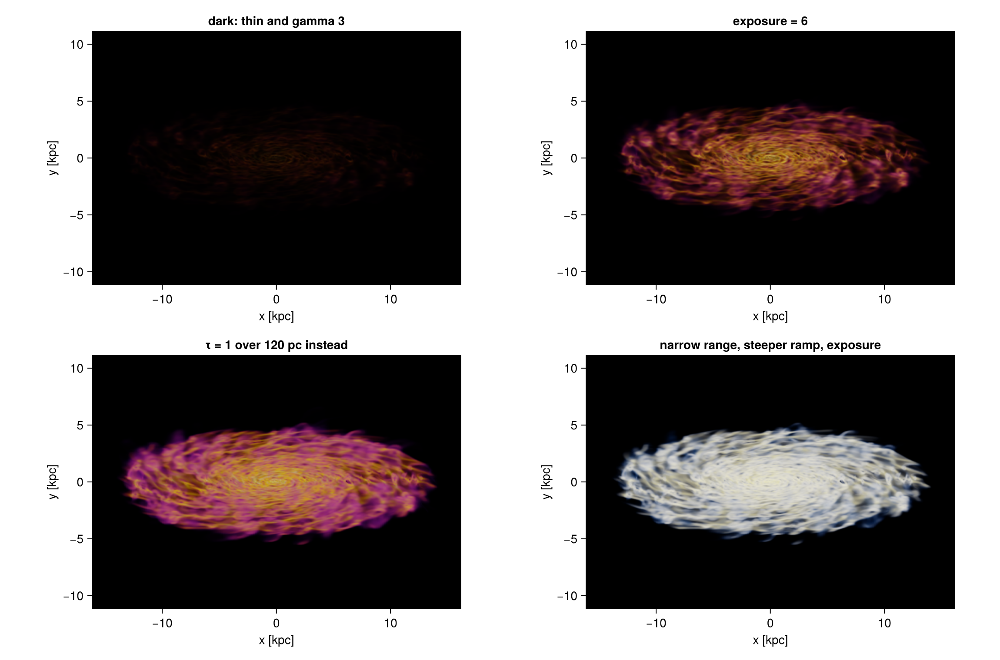

In [6]:
thin = (unit=:nH, colorrange=(1e-3, 1e2), colormap=:inferno, opacity_gamma=3,
        tau_unit_length=[3000, :pc])            # deliberately too transparent
fig = Figure(size=(1150, 760))
show_image!(fig[1, 1], volumerender(gas, :rho; thin..., panel...); title="dark: thin and gamma 3")
show_image!(fig[1, 2], volumerender(gas, :rho; thin..., exposure=6, panel...); title="exposure = 6")
show_image!(fig[2, 1], volumerender(gas, :rho; thin..., tau_unit_length=[120, :pc], panel...);
            title="τ = 1 over 120 pc instead")
show_image!(fig[2, 2], volumerender(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), colormap=:cividis,
                                    opacity_gamma=2.5, tau_unit_length=[120, :pc], exposure=2.5, panel...);
            title="narrow range, steeper ramp, exposure")
fig

## 7. Colour range, ramp and gamma

The three panels use the same data, the same opacity per length and the same exposure. Only the
colour range and the shape of the opacity ramp change, and that alone decides how far into the
galaxy you can see.

* **Wide range, straight ramp.** The range starts at 10⁻⁴ cm⁻³, so the thin halo already gets
  colour and opacity. Every line of sight collects a little of it and the disc vanishes behind an
  even haze. This is the most common way to lose a rendering.
* **Wide range, gamma 3.** The same range, but the ramp is bent: a cell only becomes opaque near
  the top of it. The haze turns transparent, the spiral arms and the holes blown by feedback come
  back, and the faint outer gas stays as a halo around them.
* **Narrow range, gamma 2.5.** The range starts at 10⁻² cm⁻³, so the halo gets no opacity at all
  and the whole colour scale is spent on the disc. This is the crispest of the three, at the price
  of the outer gas.

The rule: **the colour range decides what is in the picture, the gamma decides what is solid.**
Widen the range to keep the faint gas, then raise the gamma until it stops hiding the structure.


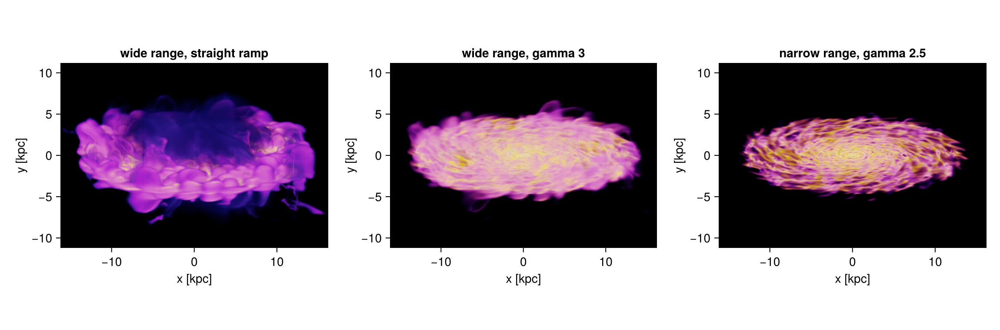

In [7]:
fig = Figure(size=(1150, 380))
settings = [("wide range, straight ramp", (1e-4, 1e2), 1.0),
            ("wide range, gamma 3",       (1e-4, 1e2), 3.0),
            ("narrow range, gamma 2.5",   (1e-2, 1e2), 2.5)]
for (k, (title, cr, g)) in enumerate(settings)
    mk = volumerender(gas, :rho; unit=:nH, colorrange=cr, colormap=:inferno, opacity_gamma=g,
                      tau_unit_length=[120, :pc], exposure=2.5, panel...)
    show_image!(fig[1, k], mk; title=title)
end
fig

## 8. Isosurfaces

`iso=[…]` puts a **surface** at each value: only gas within `iso_width` of it is opaque,
everything else stays see-through. Values far apart pick out structures of very different size.
The three panels use **10⁻³**, **10⁻¹** and **10 cm⁻³**.

Choose values the data actually has. This galaxy reaches 103 cm⁻³, so a surface at 100 cm⁻³
catches four cells and draws nothing.

* `iso_width` is the half width of a shell, in the units of the colour scale: **dex** when
  `scale=:log`, the units of the quantity when `scale=:linear`. Keep it small, 0.04 dex here, so
  the shell stays thin enough to see through.
* `iso_alpha` is how solid the centre of a shell is, one number or **one per shell**. A surface at
  a low value wraps around everything inside it, so it needs the smallest value of the three.
* `exposure` rises from panel to panel. A surface at a high value is small and catches little
  light, so it needs more.
* **Leave a faint haze underneath.** A surface on its own has a single colour, nothing says which
  part of it is near and which is far, and it reads as a tangle. `opacity=(0, 0.04)` keeps a thin
  continuous glow between the surfaces, the shell then sits in front of something, and its shape
  appears. That one setting is the whole difference here.

### When a surface comes out as scattered dots

A surface is drawn from the cells whose value falls inside `iso_width`. Where the data holds few
cells at that value, or where the quantity changes steeply from one cell to the next, the band
catches isolated cells instead of a connected sheet, and the picture is speckled.

Two different causes look alike, so it is worth telling them apart before changing settings.

**Not enough samples.** A renderer that marches a ray in steps can step straight over a thin band.
Mera does not march: every cell contributes its exact path length, and the cells are composited in
their exact front-to-back order, so there is no step size, and the banding, moire and wood-grain
patterns that come with ray marching do not arise. `supersample` decides how a pixel averages what
lies behind it, not which cells exist. If raising it changes nothing, the dots are real cells and
the cause is the other one.

**Not enough data.** Then the cure has to act on the band or on the field, and the one that works
is to **widen `iso_width`** until the shell holds enough cells to join up. That is the remedy the
literature names. Engel, Kraus and Ertl (*High-Quality Pre-Integrated Volume Rendering Using
Hardware-Accelerated Pixel Shading*, Graphics Hardware 2001) show that the sampling rate a volume
rendering needs is the product of the Nyquist frequencies of the field and of the transfer
function, so halving the width of a band doubles what it demands, and note that such artefacts
"are frequently observed unless they are avoided by very smooth transfer functions". Knoll et al.
(*Volume Ray Casting with Peak Finding and Differential Sampling*, IEEE TVCG 15, 1571, 2009) give
the limiting case: an isosurface is a transfer function with a Dirac impulse in it, and drawing one
without artefacts requires "either infinite sampling or smoothing of the transfer function".

Two cautions on how to widen:

* **Widen only where it is needed.** A wider band everywhere costs the detail a thin one buys.
  Open it over the range that is thin, and leave it alone elsewhere.
* **Do not widen until every band holds the same amount of gas.** A band that grows until it
  reaches a nearby peak in the distribution shows you that peak rather than the value you asked
  for, which is worse than speckle because it looks correct.

The gallery recipe
[A temperature sweep through a galaxy](https://github.com/ManuelBehrendt/Notebooks/tree/master/Mera-Docs/version_1.1/gallery/004_temperature_sweep)
does exactly this, with the numbers worked out on a real snapshot.


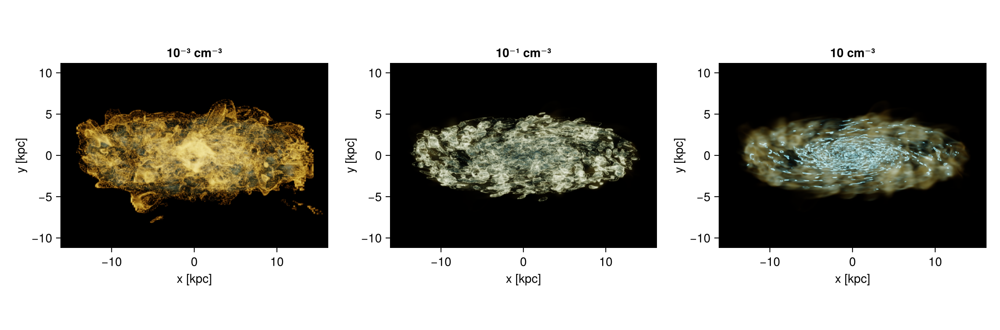

In [8]:
shells = [1e-3, 1e-1, 1e1]               # cm⁻³: three very different scales of structure
alphas = [0.25, 0.30, 0.80]              # the surface that wraps everything is the faintest
expos  = [6, 7, 14]                      # a small surface catches less light
labels = ["10⁻³ cm⁻³", "10⁻¹ cm⁻³", "10 cm⁻³"]
iso_kw = (unit=:nH, colorrange=(1e-4, 1e3), colormap=:roma, iso_width=0.04,
          opacity=(0.0, 0.04), opacity_gamma=2.5,      # the faint haze the surfaces sit in
          tau_unit_length=[500, :pc])

fig = Figure(size=(1150, 380))
for (k, (v, a, e, lab)) in enumerate(zip(shells, alphas, expos, labels))
    mk = volumerender(gas, :rho; iso=[v], iso_alpha=a, exposure=e, iso_kw..., panel...)
    show_image!(fig[1, k], mk; title=lab)
end
fig


## 9. Other quantities

Any quantity works, and these two show what changes when the field is not a density.

**Temperature** fills the whole volume, so a wide range turns it into fog. Give it a **narrow**
`colorrange` around the phase you want, 10⁶ to 10⁷ K here, a **steep** `opacity_gamma` so only
that phase is solid, and a **long** `tau_unit_length`: the hot gas is smooth and deep, and a short
one would turn it into a wall. What is left is the hot outflow above and below the disc.

**Line-of-sight velocity** is a quantity the renderer works out itself, `:vlos`, because it
depends on where the camera is. It is signed, so it needs `scale=:linear`, a `colorrange`
symmetric about zero and a diverging colour map; `:vik` is one that stays readable for
colour-blind readers. Two surfaces at ±100 km/s then separate the gas coming toward you from the
gas going away, which for a disc seen at 70° splits it cleanly in half. On a linear scale
`iso_width` is in the units of the quantity, so `iso_width=8` is a shell 8 km/s wide.

Keep those two surfaces **translucent**, with a small `iso_alpha` and a long `tau_unit_length`.
Made solid they fill in as two flat blocks of colour and the picture says only which half is
which. Translucent, the near side and the far side of each surface show through one another, the
two colours interleave where the arms cross the line of sight, and the rotation becomes visible
rather than merely labelled.


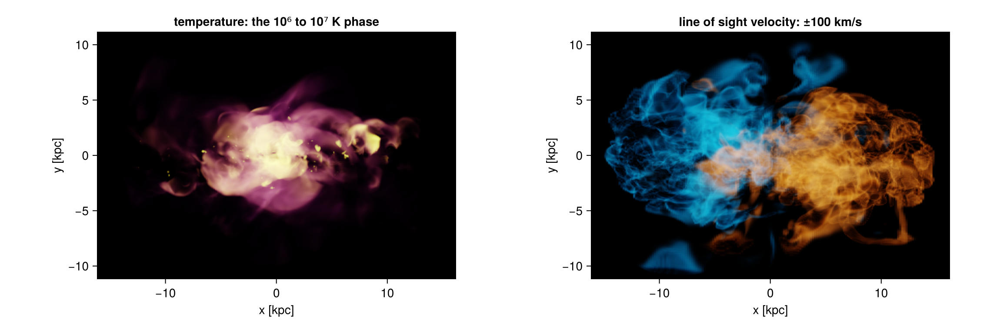

In [9]:
fig = Figure(size=(1150, 380))
mt = volumerender(gas, :T; unit=:K, colorrange=(1e6, 1e7), colormap=:plasma, opacity=(0.0, 0.5),
                  opacity_gamma=6, tau_unit_length=[900, :pc], exposure=8, panel...)
show_image!(fig[1, 1], mt; title="temperature: the 10⁶ to 10⁷ K phase")
mv = volumerender(gas, :vlos; unit=:km_s, scale=:linear, colorrange=(-150, 150), colormap=:vik,
                  opacity=(0.0, 0.0), iso=[-100.0, 100.0], iso_alpha=[0.2, 0.2], iso_width=8.0,
                  tau_unit_length=[1800, :pc], exposure=5, panel...)
show_image!(fig[1, 2], mv; title="line of sight velocity: ±100 km/s")
fig


Besides the picture, a render carries two maps: `alpha`, how much of each pixel is filled, and
`value`, the value of the quantity you actually see along that line of sight.

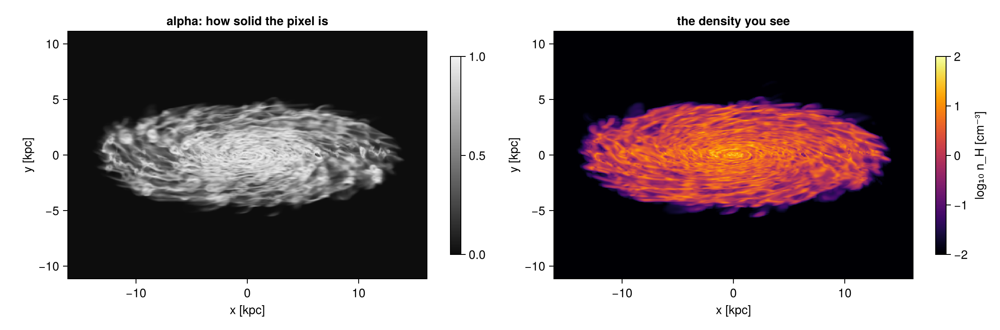

In [10]:
x0, x1, y0, y1 = getextent(m, :kpc)
fig = Figure(size=(1150, 380))
ax1 = Axis(fig[1, 1], title="alpha: how solid the pixel is", xlabel="x [kpc]", ylabel="y [kpc]", aspect=DataAspect())
hm1 = heatmap!(ax1, x0..x1, y0..y1, m.alpha, colormap=:grays, colorrange=(0, 1))
Colorbar(fig[1, 2], hm1, height=Relative(0.8))
ax2 = Axis(fig[1, 3], title="the density you see", xlabel="x [kpc]", ylabel="y [kpc]", aspect=DataAspect())
hm2 = heatmap!(ax2, x0..x1, y0..y1, log10.(replace(m.value, NaN => 1e-6)), colormap=:inferno, colorrange=(-2, 2))
Colorbar(fig[1, 4], hm2, label="log₁₀ n_H [cm⁻³]", height=Relative(0.8))
fig

## 10. Choosing the view

The view keywords are those of the off-axis [`projection`](@ref): `direction` (`:x`, `:y`, `:z`,
`:faceon`, `:edgeon`), or `inclination` and `azimuth` about a reference `axis` (`:angmom` is the
object's own spin axis), plus `position_angle` to roll the picture and `xrange`/`yrange`/`zrange`
to cut the volume.

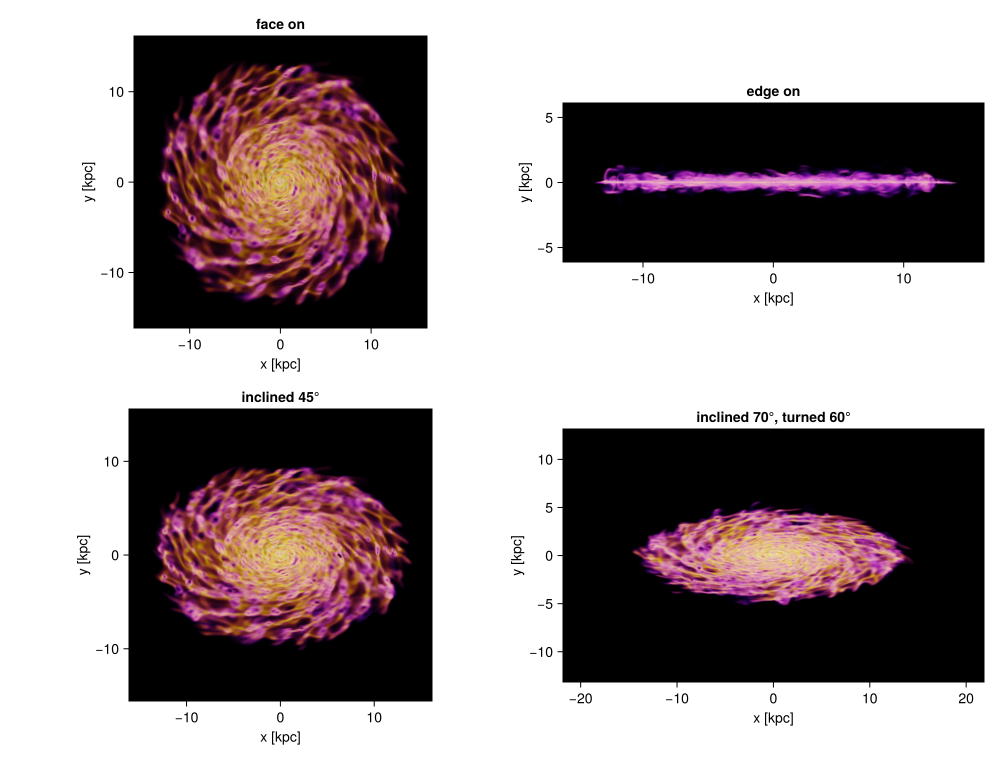

In [11]:
look = volumelook(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), colormap=:inferno,
                  opacity_gamma=2.5, tau_unit_length=[120, :pc], exposure=2.5, panel...)  # one look for all four
fig = Figure(size=(1000, 760))
for (k, (title, kw)) in enumerate([("face on",      (direction=:faceon,)),
                                   ("edge on",      (direction=:edgeon,)),
                                   ("inclined 45°", (inclination=45, axis=:angmom)),
                                   ("inclined 70°, turned 60°", (inclination=70, azimuth=60, axis=:angmom))])
    mk = volumerender(gas, :rho; look=look, Base.structdiff(panel, (inclination=0, axis=:z))..., kw...)
    show_image!(fig[(k-1) ÷ 2 + 1, (k-1) % 2 + 1], mk; title=title)
end
fig

## 11. Movies: orbits

`volumeorbit` turns the view around the object. It selects a **sphere** around the centre, so every
frame shares one field of view and the galaxy does not appear to zoom, and it resolves the look
once, so the colours and the opacity do not flicker.

```julia
frames = volumeorbit(gas, :rho; unit=:nH, angles=0:2:358, inclination=70, fov=16, fov_unit=:kpc,
                     colorrange=(1e-2, 1e2), tau_unit_length=[120, :pc], opacity_gamma=2.5,
                     exposure=2.5, pxsize=[60, :pc])
mkpath("frames")
for (k, f) in enumerate(frames)
    save(joinpath("frames", "f" * lpad(k, 4, '0') * ".png"), rotl90(f.image))
end
moviefromframes("frames", "orbit.gif"; fps=25)
```

6 frames of 

(540, 543) pixels, one look: true


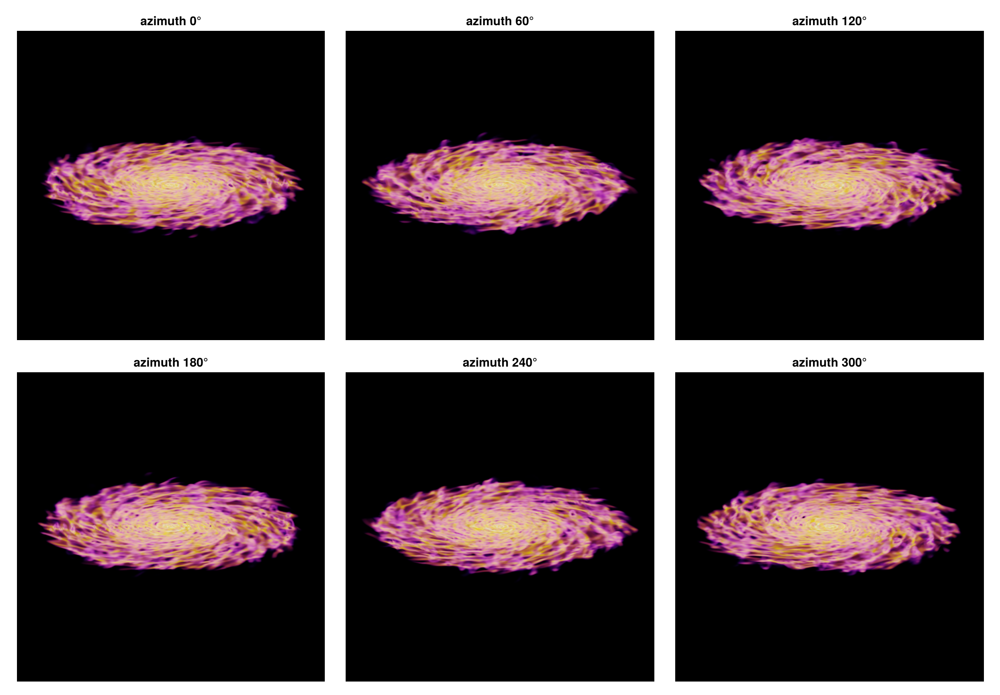

In [12]:
orbit = volumeorbit(gas, :rho; unit=:nH, angles=0:60:300, inclination=70, fov=16, fov_unit=:kpc,
                    center=[:bc], pxsize=[60, :pc], colorrange=(1e-2, 1e2), colormap=:inferno,
                    opacity_gamma=2.5, tau_unit_length=[120, :pc], exposure=2.5, verbose=false)
println(length(orbit), " frames of ", size(orbit[1].image), " pixels, one look: ",
        all(f -> f.look === orbit[1].look, orbit))

fig = Figure(size=(1150, 800))
for (k, f) in enumerate(orbit)
    ax = Axis(fig[(k-1) ÷ 3 + 1, (k-1) % 3 + 1], title="azimuth $(60*(k-1))°", aspect=DataAspect())
    hidedecorations!(ax)
    image!(ax, f.image)
end
fig

## 12. Movies: a camera path

`volumepath` moves the camera between keyframes. Each keyframe can set `inclination`, `azimuth`,
`position_angle`, `fov` (half the width of the picture, so smaller means closer) and `center`;
anything left out keeps its previous value. Angles and centres move in a straight line, the zoom
moves geometrically, and each segment is eased in and out. Every frame is cropped to exactly `res`
pixels, which a movie needs.

pixel size per frame [pc]: 

[72.6, 72.6, 72.6, 64.4, 34.2, 22.7]


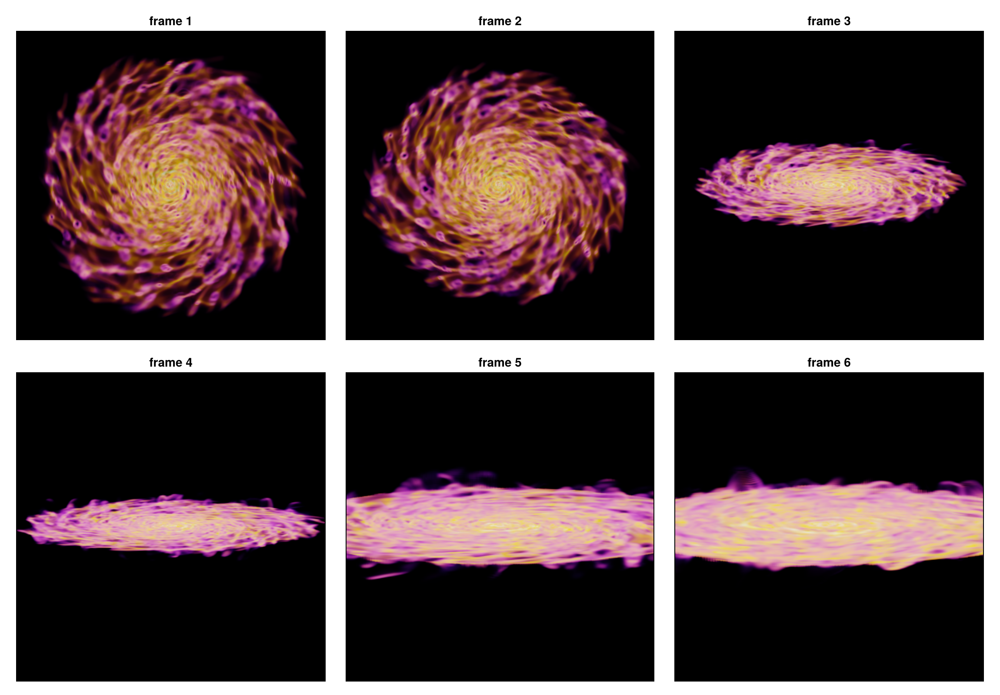

In [13]:
path = volumepath(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), colormap=:inferno,
                  opacity_gamma=2.5, tau_unit_length=[120, :pc], exposure=2.5,
                  keyframes=[(inclination=0,  azimuth=0,   fov=16),    # face on, wide
                             (inclination=80, azimuth=120, fov=16),    # tilt and turn
                             (inclination=80, azimuth=240, fov=5)],    # turn on and move in
                  frames=6, res=440, fov_unit=:kpc, verbose=false)
println("pixel size per frame [pc]: ", round.([f.pixsize * gas.scale.pc for f in path], digits=1))

fig = Figure(size=(1150, 800))
for (k, f) in enumerate(path)
    ax = Axis(fig[(k-1) ÷ 3 + 1, (k-1) % 3 + 1], title="frame $k", aspect=DataAspect())
    hidedecorations!(ax)
    image!(ax, f.image)
end
fig

## 13. How the cost scales

Two numbers decide how long a render takes, and they behave very differently.

* **The number of cells sets the cost**, in a straight line: twice the cells, twice the time. Cut
  the volume with `xrange`/`yrange`/`zrange` or a [`subregion`](@ref) and it gets faster in
  proportion.
* **Pixels are cheap.** Most cells are smaller than a pixel, and such a cell costs the same
  whatever the resolution is, so only the few large cells feel the resolution. A finer picture is
  cheap; a bigger volume is not.

`supersample` adds a modest amount per level, not the square of it, for the same reason.

Both plots below are measured while the page is built, on this galaxy, with one fixed look so that
only the amount of work changes. Both axes are logarithmic, so a straight line is a power law and
its slope is the exponent, printed above the figure.

* **Left: time against megapixels.** Four points, one per pixel size: 240, 120, 60 and 30 pc.
  The slope is about 0.15, so going from 240 pc to 30 pc pixels, sixty-four times as many, costs
  about twice the time instead of sixty-four times.
* **Right: time against the number of cells.** Three points, because the volume is cut three ways
  and not four: spheres of 4, 8 and 16 kpc radius around the centre. The grey dashed line is
  exactly linear, and the measurement runs parallel to it, a touch steeper at cells^1.1, because a
  larger volume also holds more of the coarse cells that each cover many pixels.

In both panels the grey line is what the cost would be if it followed the axis one for one. On
the left the measurement stays far below it, on the right it lies along it.


pixel size 240 pc: (

137, 95)  7.18 s


pixel size 120 pc: (

271, 187)  7.34 s


pixel size 60 pc: (

...

 cells  0.75 s


sphere of 8 kpc: 6626805

 cells  2.58 s


sphere of 16 kpc: 20737653

 cells  7.41 s

time ~ pixels^0.15   and   time ~ cells^1.07


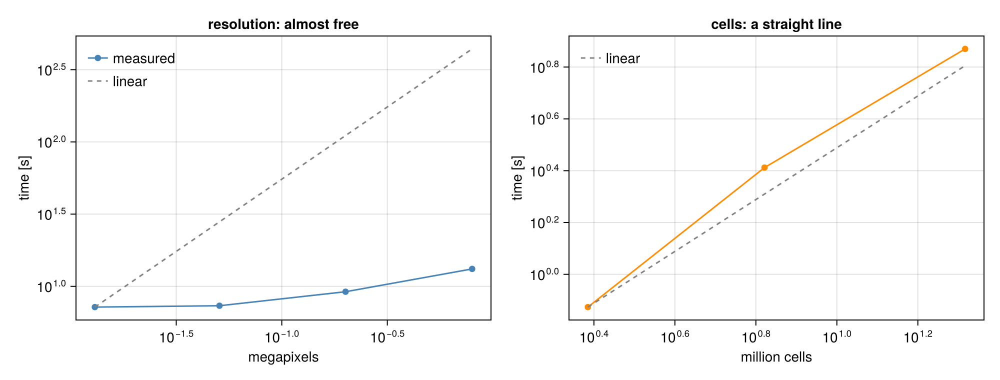

In [14]:
look_s = volumelook(gas, :rho; unit=:nH, colorrange=(1e-2, 1e2), opacity_gamma=2.5,
                    tau_unit_length=[120, :pc], exposure=2.5, panel...)
pix = Float64[]; tpix = Float64[]
for px in (240, 120, 60, 30)
    volumerender(gas, :rho; look=look_s, Base.setindex(view, [px, :pc], :pxsize)..., supersample=1)
    t = @elapsed mk = volumerender(gas, :rho; look=look_s,
                                   Base.setindex(view, [px, :pc], :pxsize)..., supersample=1)
    push!(pix, prod(size(mk.image)) / 1e6); push!(tpix, t)
    println("pixel size $px pc: ", size(mk.image), "  ", round(t, digits=2), " s")
end

ncell = Float64[]; tcell = Float64[]
for radius in (4, 8, 16)
    sub = subregion(gas, :sphere, radius=radius, center=[:bc], range_unit=:kpc, verbose=false)
    lk = volumelook(sub, :rho; unit=:nH, colorrange=(1e-2, 1e2), opacity_gamma=2.5,
                    tau_unit_length=[120, :pc], exposure=2.5, panel...)
    volumerender(sub, :rho; look=lk, panel..., supersample=1)
    t = @elapsed volumerender(sub, :rho; look=lk, panel..., supersample=1)
    push!(ncell, length(sub.data) / 1e6); push!(tcell, t)
    println("sphere of $radius kpc: ", length(sub.data), " cells  ", round(t, digits=2), " s")
end

slope(x, y) = (log(y[end]) - log(y[1])) / (log(x[end]) - log(x[1]))
println("\ntime ~ pixels^", round(slope(pix, tpix), digits=2),
        "   and   time ~ cells^", round(slope(ncell, tcell), digits=2))

fig = Figure(size=(1000, 380))
ax1 = Axis(fig[1, 1], xscale=log10, yscale=log10, xlabel="megapixels", ylabel="time [s]",
           title="resolution: almost free")
scatterlines!(ax1, pix, tpix, color=:steelblue, label="measured")
lines!(ax1, pix, tpix[1] .* pix ./ pix[1], color=:gray, linestyle=:dash, label="linear")
axislegend(ax1, position=:lt, framevisible=false)
ax2 = Axis(fig[1, 2], xscale=log10, yscale=log10, xlabel="million cells", ylabel="time [s]",
           title="cells: a straight line")
scatterlines!(ax2, ncell, tcell, color=:darkorange)
lines!(ax2, ncell, tcell[1] .* ncell ./ ncell[1], color=:gray, linestyle=:dash, label="linear")
axislegend(ax2, position=:lt, framevisible=false)
fig

## 14. What it is, and what it is not

* **An illustration.** Colour and opacity are choices. Nothing here is a surface brightness or an
  optical depth of a real observation; use [`projection`](@ref) for maps with units.
* **Exact geometry.** Each cell contributes its true path length, and the cells are composited in
  the exact front-to-back order of the AMR grid, so there is no sampling noise and no step size.
* **Orthographic.** The camera looks at the object from outside, with parallel rays. It can circle
  the object, move and zoom, but it cannot fly through the gas: that needs a perspective camera.
* **Threads.** Rendering uses all available threads; `max_threads` caps it. Start Julia with
  `julia -t 8` for the timings on this page.
* Keep one [`volumelook`](@ref) for a whole movie, otherwise the colours shift from frame to frame.

API: [`volumerender`](@ref), [`volumelook`](@ref), [`volumeorbit`](@ref), [`volumepath`](@ref),
[`VolumeRenderType`](@ref), [`VolumeLook`](@ref).